In [2]:
!pip -q install easyocr opencv-python-headless matplotlib pillow datasets jiwer streamlit

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import easyocr
import torch

from PIL import Image
from google.colab import files

print("GPU available:", torch.cuda.is_available())

reader = easyocr.Reader(
    ['en'],
    gpu=torch.cuda.is_available()
)


GPU available: True
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Saving Berlitz Level 3.jpeg to Berlitz Level 3.jpeg


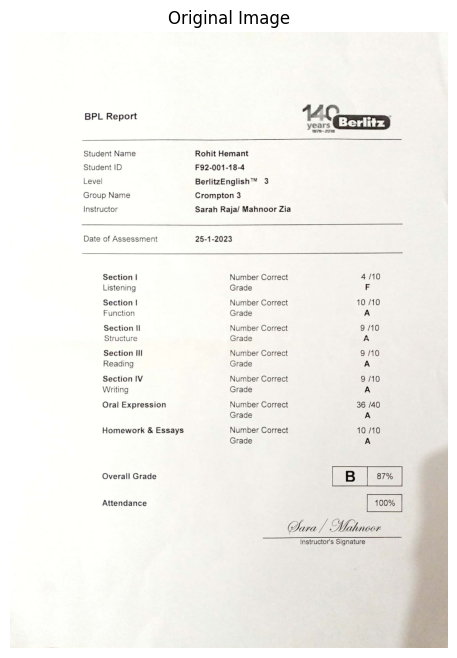

In [4]:

uploaded = files.upload()

filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    raise ValueError("Could not read the uploaded image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()


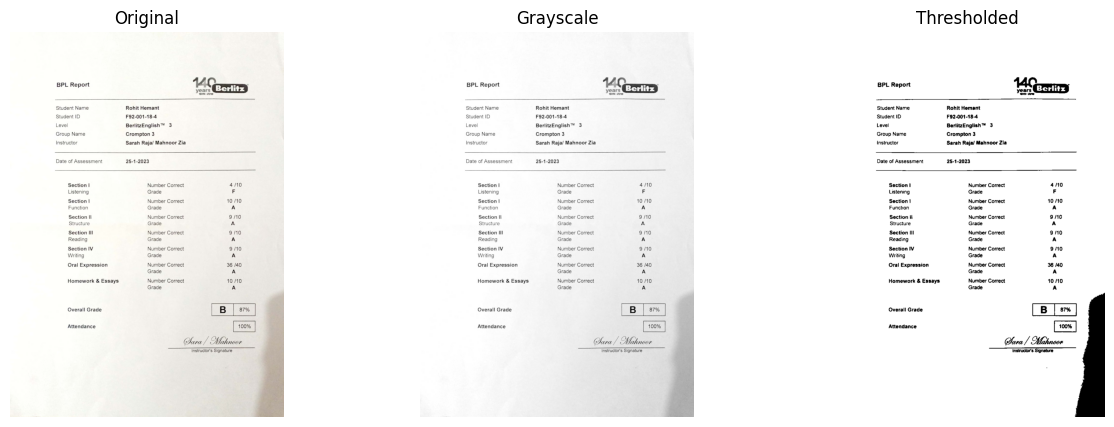

In [5]:

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

denoised = cv2.GaussianBlur(gray, (3, 3), 0)

_, thresholded = cv2.threshold(
    denoised,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")

axes[2].imshow(thresholded, cmap="gray")
axes[2].set_title("Thresholded")

for ax in axes:
    ax.axis("off")

plt.show()


In [6]:

results = reader.readtext(image_rgb)

print("Detected text:")

for bbox, text, confidence in results:
    print(f"{text} | Confidence: {confidence:.2f}")


Detected text:
BPL Report | Confidence: 1.00
VQ | Confidence: 0.19
years | Confidence: 0.99
Berlitz | Confidence: 0.98
1678-7018 | Confidence: 0.15
Student Name | Confidence: 1.00
Rohit Hemant | Confidence: 0.82
Student ID | Confidence: 0.70
F92-001-18-4 | Confidence: 0.58
Level | Confidence: 1.00
BerlitzEnglish TM | Confidence: 0.86
Group Name | Confidence: 0.78
Crompton 3 | Confidence: 1.00
Instructor | Confidence: 1.00
Sarah Rajal Mahnoor Zia | Confidence: 0.90
Date of Assessment | Confidence: 0.76
25-1-2023 | Confidence: 0.67
Section | Confidence: 1.00
Number Correct | Confidence: 1.00
4 /10 | Confidence: 0.60
Listening | Confidence: 1.00
Grade | Confidence: 0.99
Section | Confidence: 1.00
Number Correct | Confidence: 0.78
10 /10 | Confidence: 0.62
Function | Confidence: 0.91
Grade | Confidence: 1.00
Section Il | Confidence: 0.68
Number Correct | Confidence: 0.98
9 /10 | Confidence: 0.88
Structure | Confidence: 0.67
Grade | Confidence: 0.98
Section III | Confidence: 0.57
Number Cor

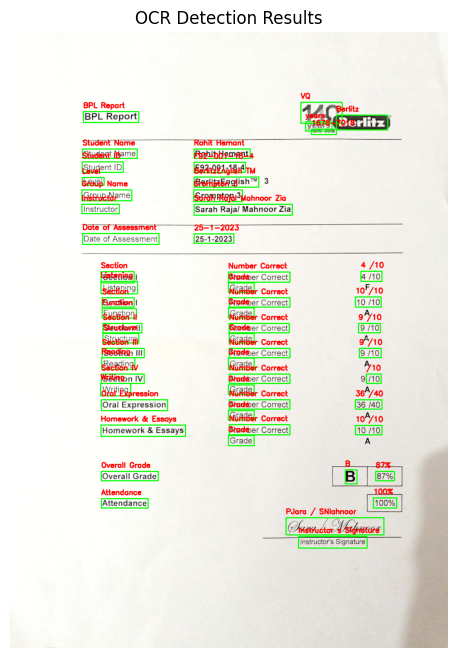

In [7]:

output_image = image_rgb.copy()

for bbox, text, confidence in results:
    points = np.array(bbox, dtype=np.int32)

    cv2.polylines(
        output_image,
        [points],
        isClosed=True,
        color=(0, 255, 0),
        thickness=2
    )

    x, y = points[0]

    cv2.putText(
        output_image,
        text,
        (int(x), max(20, int(y) - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(12, 8))
plt.imshow(output_image)
plt.title("OCR Detection Results")
plt.axis("off")
plt.show()


In [8]:

extracted_text = "\n".join(
    text for bbox, text, confidence in results
)

print(extracted_text)

with open("extracted_text.txt", "w", encoding="utf-8") as f:
    f.write(extracted_text)

files.download("extracted_text.txt")


BPL Report
VQ
years
Berlitz
1678-7018
Student Name
Rohit Hemant
Student ID
F92-001-18-4
Level
BerlitzEnglish TM
Group Name
Crompton 3
Instructor
Sarah Rajal Mahnoor Zia
Date of Assessment
25-1-2023
Section
Number Correct
4 /10
Listening
Grade
Section
Number Correct
10 /10
Function
Grade
Section Il
Number Correct
9 /10
Structure
Grade
Section III
Number Correct
9 /10
Reading
Grade
Section IV
Number Correct
/10
Writing
Grade
Oral Expression
Number Correct
36 /40
Grade
Homework & Essays
Number Correct
10 /10
Grade
Overall Grade
B
87%
Attendance
100%
PJara / SNlahnoor
Instructor s Signature


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

from datasets import load_dataset

dataset = load_dataset(
    "ilsilfverskiold/ocr-benchmark",
    split="train"
)

print("Total images:", len(dataset))
print("Available columns:", dataset.column_names)


README.md:   0%|          | 0.00/5.14k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 97.7MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Total images: 93
Available columns: ['image', 'stem', 'tier', 'doc_type', 'gt_text', 'gt_json', 'structured_gt', 'markdown_gt', 'geometry_gt']


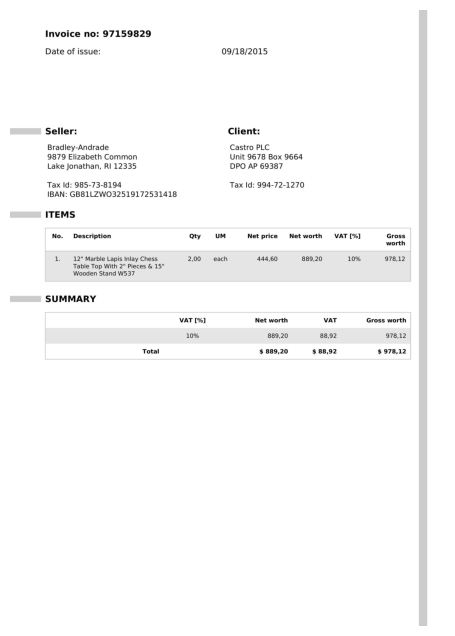

Recognized text:

Invoice no: 97159829
Date of issue:
09/18/2015
Seller:
Client:
Bradley-Andrade
Castro PLC
9879 Elizabeth Common
Unit 9678 Box 9664
Lake Jonathan, RI 12335
DPO AP 69387
Tax Id: 985-73-8194
Tax Id: 994-72-1270
IBAN: GB8ILZWO32519172531418
ITEMS
No.
Description
UM
Net price
Net worth
VAT [%]
Gross
worth
1
12" Marble Lapis Inlay Chess
2,00
each
444,60
889,20
10%
978,12
Table Top With 2" Pieces & 15"
Wooden Stand W537
SUMMARY
VAT [%]
Net worth
VAT
Gross worth
10%
889,20
88,92
978,12
Total
$ 889,20
$ 88,92
$ 978,12
Qty


In [10]:

sample = dataset[0]

img = sample["image"].convert("RGB")
img_array = np.array(img)

results = reader.readtext(img_array)

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

print("Recognized text:\n")

predicted_text = "\n".join(
    text for bbox, text, confidence in results
)

print(predicted_text)


In [11]:

from jiwer import cer, wer

reference_text = sample.get("gt_text")

if reference_text:
    print("CER:", cer(reference_text, predicted_text))
    print("WER:", wer(reference_text, predicted_text))
else:
    print("No ground-truth text for this sample.")


CER: 0.17794970986460348
WER: 0.7701149425287356
